# Heart Disease UCI Dataset — Exploratory Data Analysis

## 1. Objective

To explore and understand the Heart Disease UCI dataset by analyzing its structure, data quality, feature distributions, missing values, class balance, and relationships between features and the target variable, providing insights for subsequent data preprocessing and model development.

## 2. Dataset Acquisition

### 2.1 Import libraries

In [ ]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

sns.set_theme(style="whitegrid")

### 2.2 Define project paths

In [86]:
PROJECT_ROOT = Path.cwd().parent

DATA_DIR = PROJECT_ROOT / "data"
RAW_DATA_DIR = DATA_DIR / "raw"

RAW_DATA_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Raw data directory:", RAW_DATA_DIR)

Project root: d:\pavan_Mtech\s3\MLops\mlops-heart-disease
Raw data directory: d:\pavan_Mtech\s3\MLops\mlops-heart-disease\data\raw


### 2.3 Download Data

In [87]:
from pathlib import Path

# Create the raw data directory
RAW_DATA_DIR = Path("../data/raw")
RAW_DATA_DIR.mkdir(parents=True, exist_ok=True)

# UCI Heart Disease dataset
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/heart-disease/processed.cleveland.data"

# Column names from the UCI dataset
columns = [
    "age",
    "sex",
    "cp",
    "trestbps",
    "chol",
    "fbs",
    "restecg",
    "thalach",
    "exang",
    "oldpeak",
    "slope",
    "ca",
    "thal",
    "target"
]

# Download directly from UCI
df = pd.read_csv(
    url,
    header=None,
    names=columns,
    na_values="?" ##The UCI raw file uses ? for missing values,pandas convert those entries into proper NaN values instead of treating ? as ordinary text
)

# Save a local copy for reproducibility
output_path = RAW_DATA_DIR / "heart_disease.csv"
df.to_csv(output_path, index=False)

print("Dataset downloaded successfully!")
print("Saved to:", output_path)

Dataset downloaded successfully!
Saved to: ..\data\raw\heart_disease.csv


## 3. Dataset Overview

In [ ]:
print(df.head())

print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

df.columns.tolist()
df.info()
df.describe()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


Number of rows: 303
Number of columns: 14
<class 'pandas.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    float64
 1   sex       303 non-null    float64
 2   cp        303 non-null    float64
 3   trestbps  303 non-null    float64
 4   chol      303 non-null    float64
 5   fbs       303 non-null    float64
 6   restecg   303 non-null    float64
 7   thalach   303 non-null    float64
 8   exang     303 non-null    float64
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    float64
 11  ca        299 non-null    float64
 12  thal      301 non-null    float64
 13  target    303 non-null    int64  
dtypes: float64(13), int64(1)
memory usage: 33.3 KB


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
count,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,299.000000,301.000000,303.000000
mean,54.438944,0.679868,3.158416,131.689769,246.693069,0.148515,0.990099,149.607261,0.326733,1.039604,1.600660,0.672241,4.734219,0.937294
std,9.038662,0.467299,0.960126,17.599748,51.776918,0.356198,0.994971,22.875003,0.469794,1.161075,0.616226,0.937438,1.939706,1.228536
min,29.000000,0.000000,1.000000,94.000000,126.000000,0.000000,0.000000,71.000000,0.000000,0.000000,1.000000,0.000000,3.000000,0.000000
25%,48.000000,0.000000,3.000000,120.000000,211.000000,0.000000,0.000000,133.500000,0.000000,0.000000,1.000000,0.000000,3.000000,0.000000
50%,56.000000,1.000000,3.000000,130.000000,241.000000,0.000000,1.000000,153.000000,0.000000,0.800000,2.000000,0.000000,3.000000,0.000000
75%,61.000000,1.000000,4.000000,140.000000,275.000000,0.000000,2.000000,166.000000,1.000000,1.600000,2.000000,1.000000,7.000000,2.000000
max,77.000000,1.000000,4.000000,200.000000,564.000000,1.000000,2.000000,202.000000,1.000000,6.200000,3.000000,3.000000,7.000000,4.000000


## 4. Data Quality

### 4.1 Missing  summary

In [89]:
missing_count = df.isnull().sum()

missing_percentage = (
    df.isnull().sum() / len(df) * 100
).round(2)

missing_summary = pd.DataFrame({
    "Missing Values": missing_count,
    "Missing Percentage": missing_percentage
})

missing_summary = missing_summary.sort_values(
    by="Missing Values",
    ascending=False
)

missing_summary

,Missing Values,Missing Percentage
ca,4,1.32
thal,2,0.66
cp,0,0.00
trestbps,0,0.00
age,0,0.00
sex,0,0.00
fbs,0,0.00
chol,0,0.00
restecg,0,0.00
thalach,0,0.00


In [90]:
#Check exactly which rows are missing
df[df[["ca", "thal"]].isnull().any(axis=1)]

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
87,53.0,0.0,3.0,128.0,216.0,0.0,2.0,115.0,0.0,0.0,1.0,0.0,NaN,0
166,52.0,1.0,3.0,138.0,223.0,0.0,0.0,169.0,0.0,0.0,1.0,NaN,3.0,0
192,43.0,1.0,4.0,132.0,247.0,1.0,2.0,143.0,1.0,0.1,2.0,NaN,7.0,1
266,52.0,1.0,4.0,128.0,204.0,1.0,0.0,156.0,1.0,1.0,2.0,0.0,NaN,2
287,58.0,1.0,2.0,125.0,220.0,0.0,0.0,144.0,0.0,0.4,2.0,NaN,7.0,0
302,38.0,1.0,3.0,138.0,175.0,0.0,0.0,173.0,0.0,0.0,1.0,NaN,3.0,0


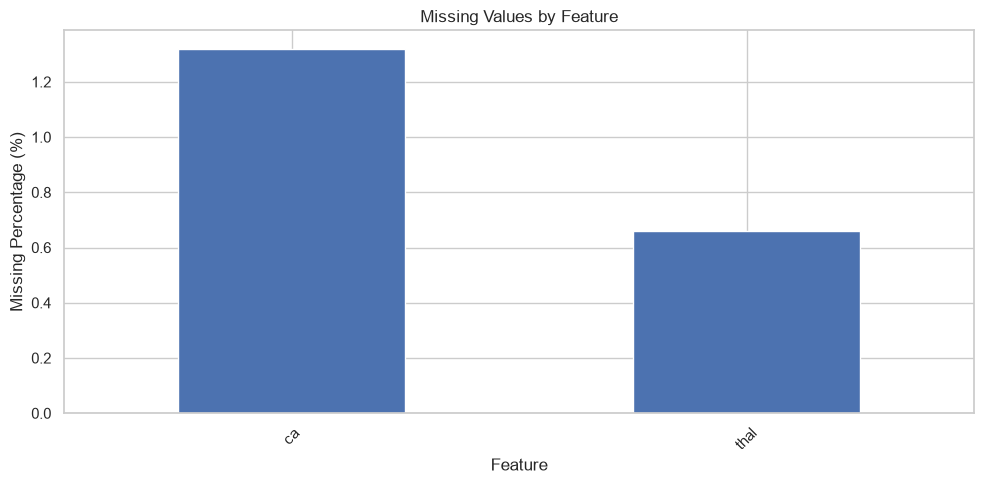

In [91]:
plt.figure(figsize=(10, 5))

missing_percentage[missing_percentage > 0].sort_values(
    ascending=False
).plot(kind="bar")

plt.title("Missing Values by Feature")
plt.xlabel("Feature")
plt.ylabel("Missing Percentage (%)")
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

### 4.2 Duplicate summary 

In [92]:
duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 0


## 5. Target Analysis

### 5.1 Check Original target distribution 

In [ ]:
target_column = "target"
class_distribution = pd.DataFrame({
    "Count": df[target_column].value_counts(),
    "Percentage": (
        df[target_column].value_counts(normalize=True) * 100
    ).round(2)
})

class_distribution

,Count,Percentage
target,,
0,164,54.13
1,139,45.87


### 5.2 Target Class-balance visualization

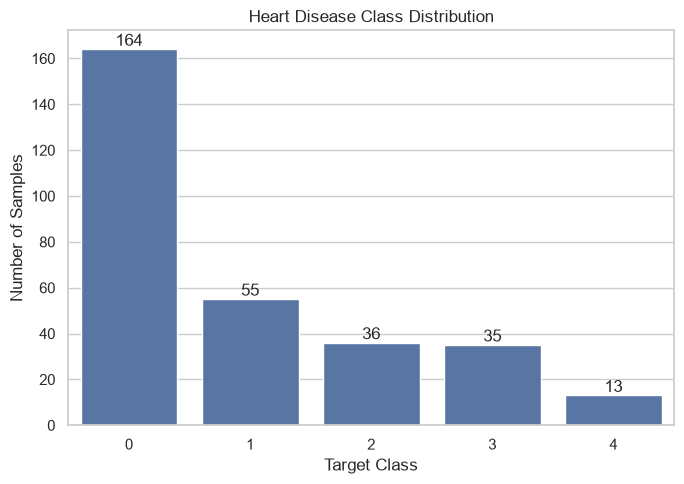

In [94]:
plt.figure(figsize=(7, 5))

ax = sns.countplot(
    data=df,
    x=target_column
)

plt.title("Heart Disease Class Distribution")
plt.xlabel("Target Class")
plt.ylabel("Number of Samples")

for container in ax.containers:
    ax.bar_label(container)

plt.tight_layout()
plt.show()

### 5.3 Convert the target to binary

In [95]:
# Convert the original UCI disease severity target
# into a binary classification target.

df["target"] = (df["target"] > 0).astype(int)

print(df["target"].value_counts().sort_index())

target
0    164
1    139
Name: count, dtype: int64


### 5.4 Create a target-label table

In [96]:
target_labels = {
    0: "No Heart Disease",
    1: "Heart Disease"
}

target_summary = pd.DataFrame({
    "Class": df["target"].value_counts().sort_index().index,
    "Count": df["target"].value_counts().sort_index().values
})

target_summary["Label"] = target_summary["Class"].map(target_labels)

target_summary["Percentage"] = (
    target_summary["Count"] / len(df) * 100
).round(2)

target_summary

,Class,Count,Label,Percentage
0,0,164,No Heart Disease,54.13
1,1,139,Heart Disease,45.87


### 5.5 Target Class visualization after binary conversion

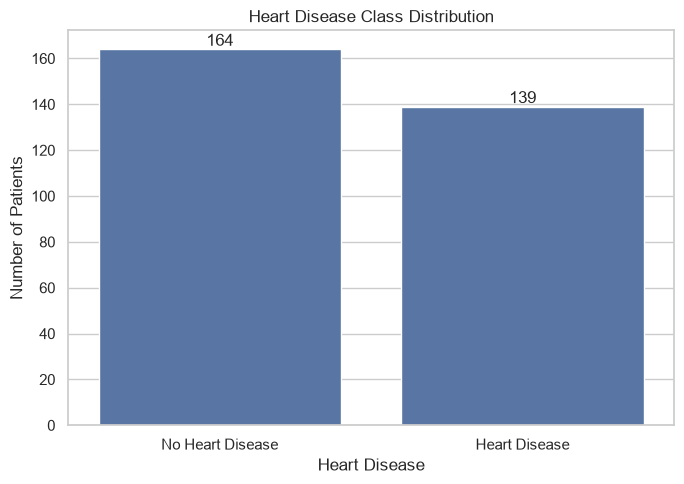

In [ ]:
plt.figure(figsize=(7, 5))

ax = sns.countplot(
    data=df,
    x="target"
)

plt.title("Heart Disease Class Distribution")
plt.xlabel("Heart Disease")
plt.ylabel("Number of Patients")

ax.set_xticks([0, 1])
ax.set_xticklabels([
    "No Heart Disease",
    "Heart Disease"
])

for container in ax.containers:
    ax.bar_label(container)

plt.tight_layout()
plot_path = "../screenshots/1_target_distribution.png"
plt.savefig(plot_path)
plt.show()

## 6. Numerical feature histograms

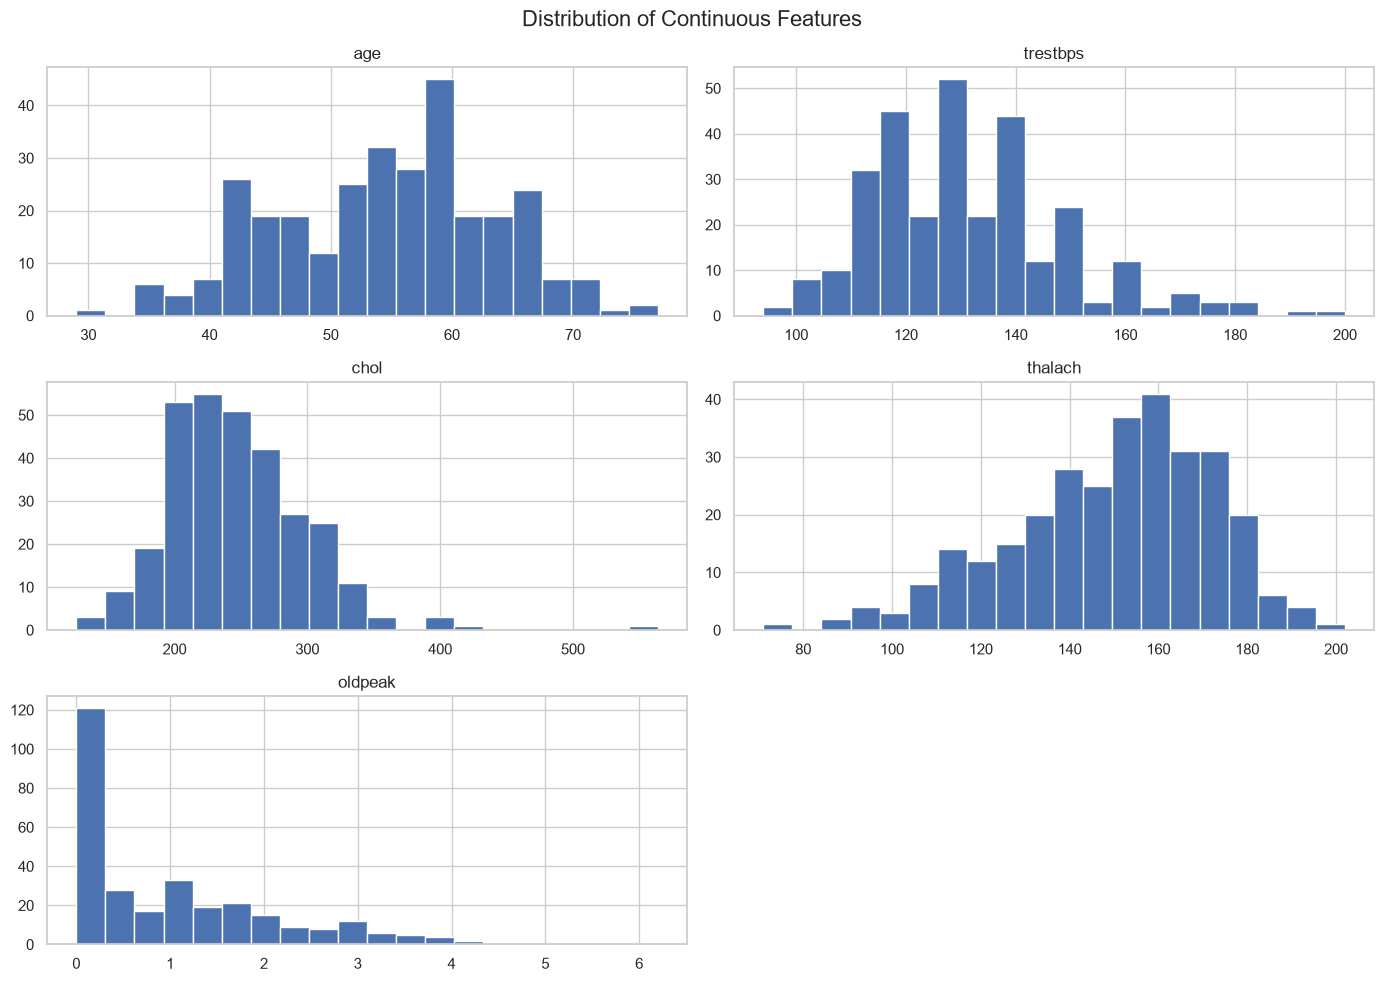

In [110]:
continuous_features = [
    "age",
    "trestbps",
    "chol",
    "thalach",
    "oldpeak"
]

df[continuous_features].hist(
    figsize=(14, 10),
    bins=20
)

plt.suptitle(
    "Distribution of Continuous Features",
    fontsize=16
)

plt.tight_layout()

plot_path = "../screenshots/2_Histograms_For_Numerical_Features.png"
plt.savefig(plot_path)
plt.show()

## 7. Boxplots for outlier analysis

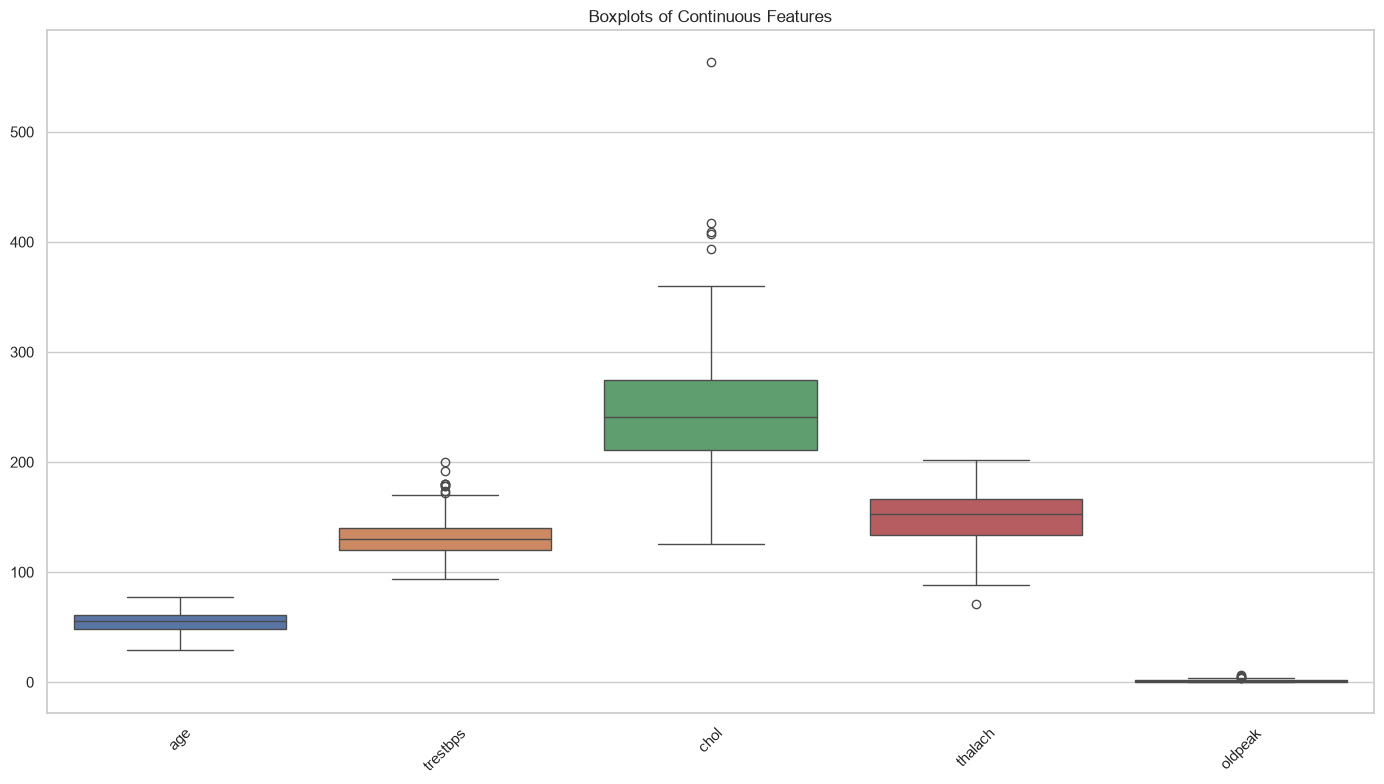

In [109]:
plt.figure(figsize=(14, 8))

sns.boxplot(
    data=df[continuous_features]
)

plt.title("Boxplots of Continuous Features")
plt.xticks(rotation=45)
plt.tight_layout()
plot_path = "../screenshots/3_Boxplots_For_Numerical_Features.png"
plt.savefig(plot_path)
plt.show()

## 8. Categorical feature distributions

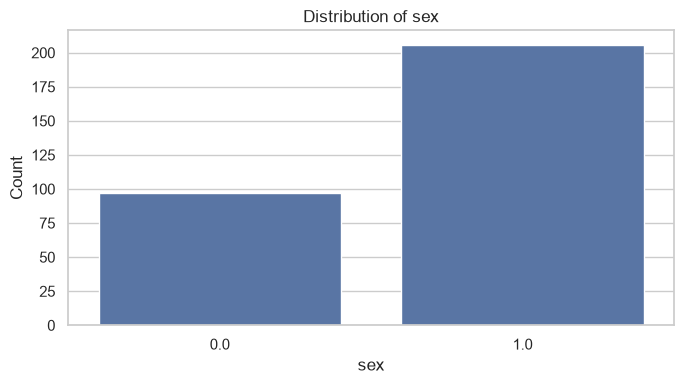

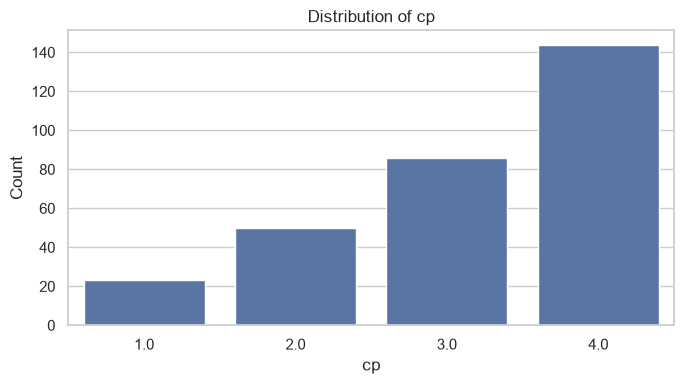

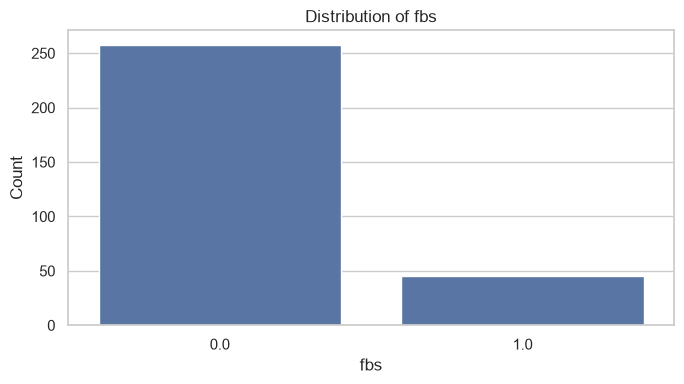

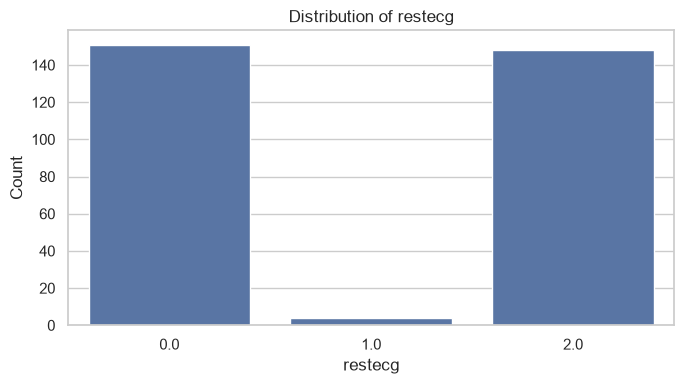

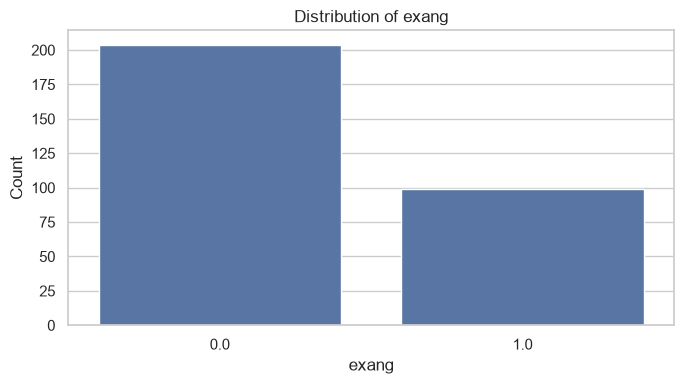

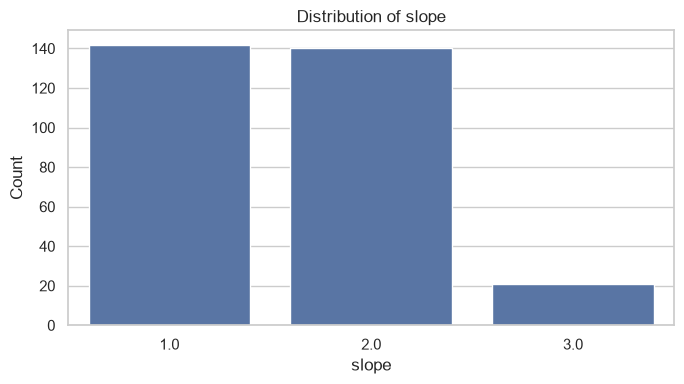

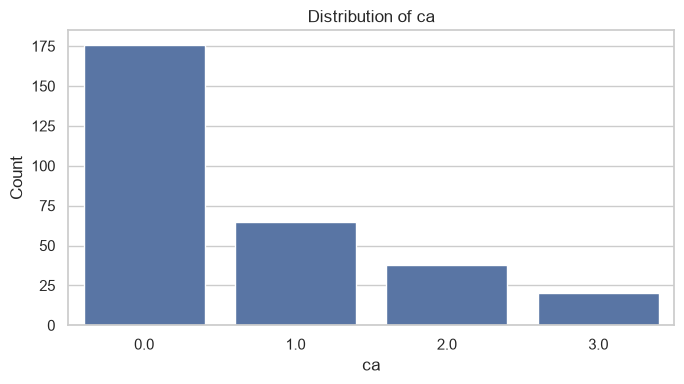

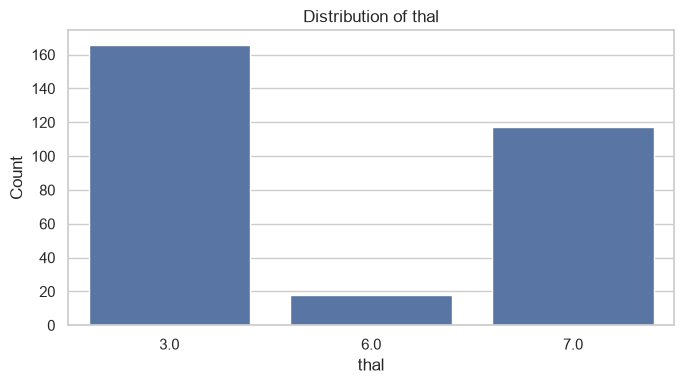

In [107]:
categorical_features = [
    "sex",
    "cp",
    "fbs",
    "restecg",
    "exang",
    "slope",
    "ca",
    "thal"
]

for column in categorical_features:
    plt.figure(figsize=(7, 4))

    sns.countplot(
        data=df,
        x=column
    )

    plt.title(f"Distribution of {column}")
    plt.xlabel(column)
    plt.ylabel("Count")

    plt.tight_layout()
    plot_path = "../screenshots/Histogram_For_"+f"Distribution_of_{column}.png"
    plt.savefig(plot_path)
    plt.show()

## 9. Correlation heatmap

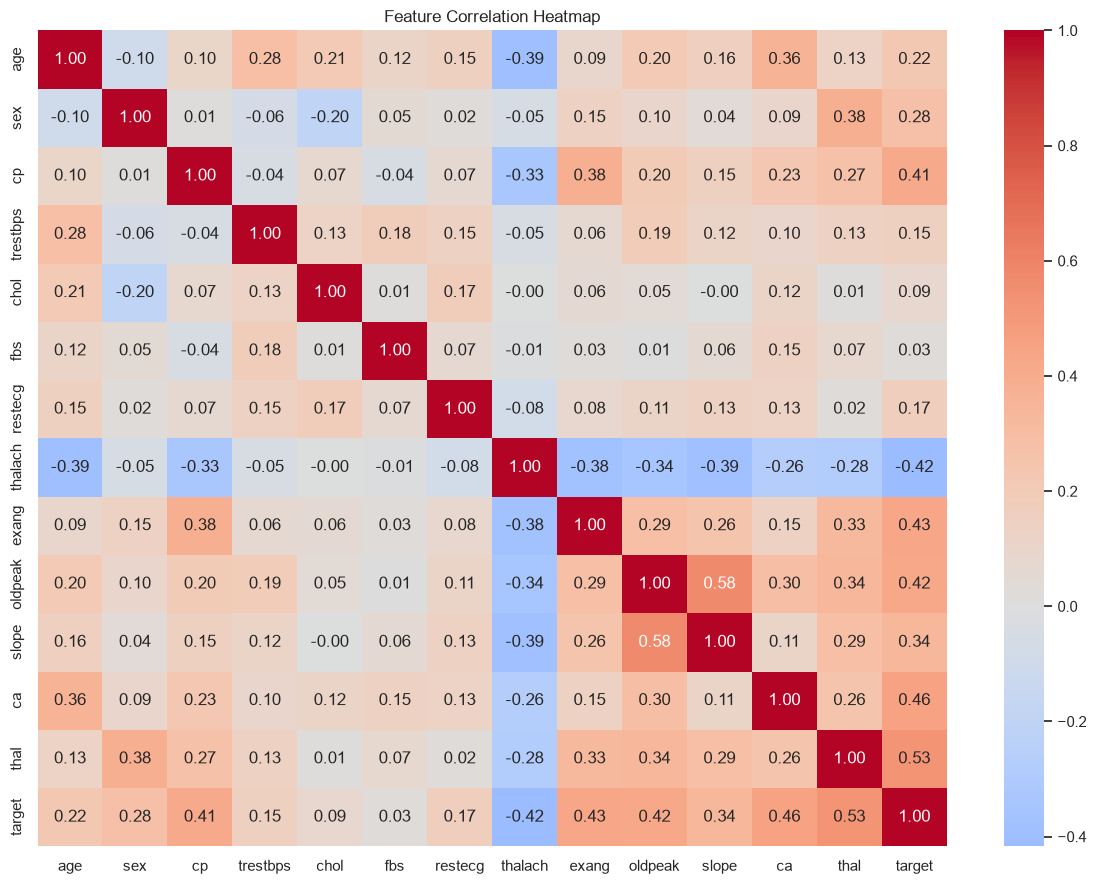

In [111]:
plt.figure(figsize=(12, 9))

correlation_matrix = df.corr(numeric_only=True)

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Feature Correlation Heatmap")
plt.tight_layout()
plot_path = "../screenshots/4_correlation_heatmap.png"
plt.savefig(plot_path)
plt.show()

## EDA Findings

The following observations were obtained from the exploratory analysis:

1. The dataset contains 303 observations and 14 columns, including 13 predictor variables and one binary target variable.
2. The target variable contains two classes: 0 representing no heart disease and 1 representing heart disease.
3. The target classes are reasonably balanced, with 164 observations (54.1%) belonging to the no-heart-disease class and 139 observations (45.9%) belonging to the heart-disease class. No severe class imbalance is observed.
4. Missing-value analysis identified missing observations in the ca and thal features. ca contains 4 missing values, while thal contains 2 missing values.
5. Duplicate-record analysis identified No duplicate records were identified in the dataset.
6.The numerical features exhibit different distribution patterns. chol and trestbps show some right skewness, while oldpeak is strongly right-skewed. age and thalach show broader distributions. Some features also contain potential extreme observations.
7. The correlation analysis indicates relatively stronger relationships between the target and thal, ca, exang, oldpeak, cp, and thalach. thalach shows a negative relationship with the target, whereas the other relatively stronger relationships are positive. chol and fbs show weak linear correlations with the target.
8.Several categorical features show uneven category frequencies. Some categories are substantially more frequent than others, particularly in sex, fbs, exang, ca, and thal. Some categories in cp, restecg, and slope are also relatively infrequent.
9. Based on the EDA, preprocessing will require missing-value imputation, appropriate encoding of categorical features, feature scaling for numerical variables, and construction of a reproducible preprocessing pipeline.